In [103]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [104]:
df = pd.read_csv('SuicideRatesDataset.csv')

In [105]:
model = LinearRegression()
df.head()

,country,country_code,year,sex,age_bracket,suicide_rate_per_100k,generation,gdp_usd,gdp_per_capita_usd,total_country_population
0,Afghanistan,AFG,2000,both,all_ages,4.36,All Cohorts,3.521418e+09,174.930991,20130327.0
1,Afghanistan,AFG,2000,female,all_ages,2.91,All Cohorts,3.521418e+09,174.930991,20130327.0
2,Afghanistan,AFG,2000,male,all_ages,5.79,All Cohorts,3.521418e+09,174.930991,20130327.0
3,Afghanistan,AFG,2001,both,all_ages,4.38,All Cohorts,2.813572e+09,138.706822,20284307.0
4,Afghanistan,AFG,2001,female,all_ages,2.92,All Cohorts,2.813572e+09,138.706822,20284307.0


In [106]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18315 entries, 0 to 18314
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   country                   18315 non-null  object 
 1   country_code              18315 non-null  object 
 2   year                      18315 non-null  int64  
 3   sex                       18315 non-null  object 
 4   age_bracket               18315 non-null  object 
 5   suicide_rate_per_100k     18315 non-null  float64
 6   generation                18315 non-null  object 
 7   gdp_usd                   18000 non-null  float64
 8   gdp_per_capita_usd        18000 non-null  float64
 9   total_country_population  18315 non-null  float64
dtypes: float64(4), int64(1), object(5)
memory usage: 1.4+ MB


In [107]:
features = ['gdp_per_capita_usd', 'total_country_population']
target_col = 'suicide_rate_per_100k'

df_clean = df[features +[target_col]].dropna(subset=features +[target_col])

X = df_clean[features]
y = df_clean[target_col]

In [108]:
df_clean.head()

,gdp_per_capita_usd,total_country_population,suicide_rate_per_100k
0,174.930991,20130327.0,4.36
1,174.930991,20130327.0,2.91
2,174.930991,20130327.0,5.79
3,138.706822,20284307.0,4.38
4,138.706822,20284307.0,2.92


In [109]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [110]:
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [111]:
predictions = model.predict(X_test)

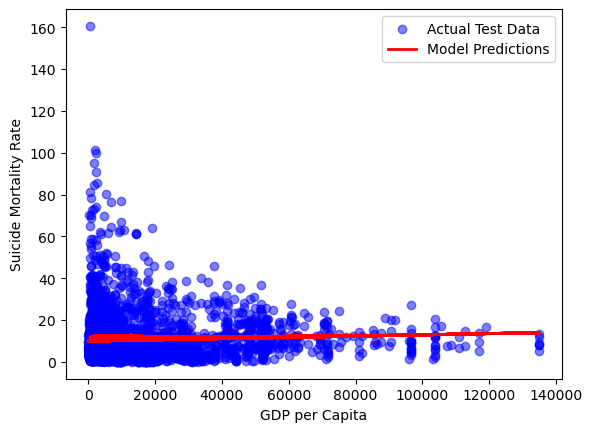

In [112]:
x_visual = X_test['gdp_per_capita_usd']

plt.scatter(x_visual, y_test, color='blue', alpha=0.5, label='Actual Test Data')
plt.plot(x_visual, predictions, color='red', linewidth=2, label='Model Predictions')

plt.xlabel('GDP per Capita')
plt.ylabel('Suicide Mortality Rate')
plt.legend()
plt.show()